# 03 - Figures of the paper

**Question.** Reproduce Figures 1-5 of the BNC2 manuscript from the pipeline outputs.

**Before running.** `python code/scripts/main.py --rasters` must have produced `results/` and `data/derived/`.

**Exports.** `results/figures/figure{1..5}.png` and `.pdf`.

Current method: four FAO GEZ biome means from Gibbs/GFW (2001-2023), applied to FRA 2025 forest area after subtracting only mangrove hectares that national reports explicitly classify as Forest. Unverified Forest/other-wooded-land overlap remains in the FRA forest total and is reported as a limitation. The forest measure is annual carbon added to above- and below-ground living biomass; it is not a net ecosystem balance or a measure of storage duration. Monetary uncertainty comes from the shared GSCC draws; the spatial SD of the rates is not sampled as rate uncertainty.

In [1]:
import os
import glob
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
# from mpl_toolkits.axes_grid1.inset_locator import inset_axes

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SUMMARY, OUTPUT = ROOT / "data" / "summary", ROOT / "output"
FIGURES = OUTPUT / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
CO2_PER_C = 44 / 12

gcw = pd.read_csv(OUTPUT / "country_level_gcw.csv")
ncw = pd.read_csv(OUTPUT / "country_level_ncw.csv")
territories = pd.read_csv(SUMMARY / "territories.csv")
areas = pd.read_csv(SUMMARY / "forest_areas.csv")
by_continent = pd.read_csv(OUTPUT / "tables" / "table2_by_continent.csv")
by_group = pd.read_csv(OUTPUT / "tables" / "table3_by_group.csv")

# Land polygons (Natural Earth) keyed on the FRA accounting units.
NE_TO_UNIT = {"SDS": "SSD", "SAH": "ESH", "PSX": "PSE", "HKG": "CHN", "MAC": "CHN", "TWN": "CHN", "CYN": "CYP",
              "SOL": "SOM", "ALD": "FIN", "ATC": "AUS", "IOA": "AUS"}
world = gpd.read_file("/vsizip/" + (ROOT / "data/raw/geospatial/boundaries/ne_50m_admin_0_countries.zip").as_posix()
                      + "/ne_50m_admin_0_countries.shp")
world["iso3"] = world["ADM0_A3"].replace(NE_TO_UNIT)
world = world.dissolve("iso3", as_index=False)[["iso3", "geometry"]]
world = world.loc[world["iso3"] != "ATA"].to_crs("+proj=robin")

GREENS = ["#e5f5e0", "#c7e9c0", "#a1d99b", "#74c476", "#31a354", "#006d2c", "#00441b"]
GROUP_COLORS = {"Developing economies": "#4c72b0", "SIDS": "#dd8452", "LDCs": "#c44e52", "Developed economies": "#55a868"}

paths = [
    r"C:\Windows\Fonts",
    os.path.expandvars(r"%LOCALAPPDATA%\Microsoft\Windows\Fonts")
]

for path in paths:
    for font in glob.glob(os.path.join(path, "*Inter*.ttf")):
        fm.fontManager.addfont(font)

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Inter", "Segoe UI", "DejaVu Sans"],
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "legend.fontsize": 8,
})

def panel_label(ax, letter, title, subtitle=""):
    """Titre de panneau: lettre en gras (mathtext) suivie du titre, aligné à gauche."""
    head = f"$\\bf{{({letter})}}$ {title}"
    ax.set_title(f"{head}\n{subtitle}" if subtitle else head, loc="left")

def choropleth(ax, values, bins, labels, colors, *texts):
    """Classed world map: `values` is a Series indexed by iso3, `bins` are the class edges.

    Two calling styles are accepted:
    - choropleth(ax, ..., colors, "a", title, subtitle)  -> bold panel label via panel_label();
    - choropleth(ax, ..., colors, title, subtitle)       -> plain title (older cells).
    The legend sits inside the map, so it never overlaps the panel below.
    """
    if texts and len(texts[0]) <= 2 and len(texts) > 1:
        letter, title, subtitle = texts[0], texts[1], texts[2] if len(texts) > 2 else ""
    else:
        letter, title, subtitle = None, texts[0], texts[1] if len(texts) > 1 else ""
    data = world.merge(values.rename("value"), left_on="iso3", right_index=True, how="left")
    data["cls"] = pd.cut(data["value"], bins=bins, labels=labels)
    data.plot(ax=ax, color="#d9d9d9", linewidth=0.1, edgecolor="white")
    for label, color in zip(labels, colors):
        subset = data.loc[data["cls"] == label]
        if not subset.empty:
            subset.plot(ax=ax, color=color, linewidth=0.1, edgecolor="white")
    handles = [Patch(color=c, label=l) for l, c in zip(labels, colors)] + [Patch(color="#d9d9d9", label="No data")]
    ax.legend(handles=handles, loc="lower left", ncol=2, framealpha=0.85)
    ax.set_axis_off()
    if letter is None:
        ax.set_title(f"{title}\n{subtitle}" if subtitle else title, fontsize=11)
    else:
        panel_label(ax, letter, title, subtitle)


SAVE_FIGURES = True  # Export refreshed figures to results/figures/*.png and *.pdf


def save(fig, name):
    """Export the figure only when SAVE_FIGURES is True (keeps quick iterations cheap)."""
    if not SAVE_FIGURES:
        print(f"[skipped] {name} not saved (SAVE_FIGURES = False)")
        return
    for ext in ("png", "pdf"):
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=300, bbox_inches="tight")
    print(f"[saved] {name}.png / {name}.pdf")

## Figure 1 - Distribution of forest area

(a) forest area by country, (b) top 5 countries and rest of the world, (c) net annual change in forest area by region. Source: FRA 2025.

[saved] figure1a.png / figure1a.pdf


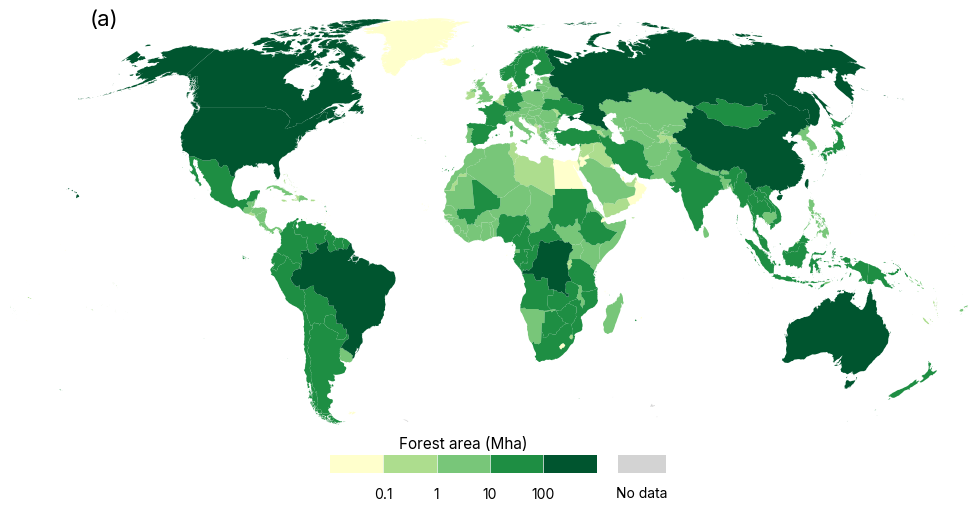

In [2]:
# Figure 1a - forest area map, BCW style (src/visualization.py: mapper_bc)
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle

COL_LIST = [
    "#ffffcc",
    "#addd8e",
    "#78c679",
    "#1E8E43",
    "#00552f"
]
FOREST_CMAP = ListedColormap(COL_LIST)
BINS = [-1, 1e5, 1e6, 1e7, 1e8, np.inf]
BIN_LABELS = ["\u2264 0.1 Mha", "0.1 \u2013 1 Mha", "1 \u2013 10 Mha", "10 \u2013 100 Mha", "> 100 Mha"]
MISSING_COLOR, MISSING_LABEL = "#D3D3D3", "No data"

forest_2025 = areas.loc[areas["year"] == 2025].set_index("iso3")["forest"]
country_data = world.merge(forest_2025.rename("value"), left_on="iso3", right_index=True, how="left")
country_data["_cat"] = pd.cut(country_data["value"], bins=BINS, labels=BIN_LABELS, include_lowest=True).astype(object)
country_data["_cat"] = country_data["_cat"].fillna(MISSING_LABEL)

colors = {MISSING_LABEL: MISSING_COLOR} | {label: FOREST_CMAP(i) for i, label in enumerate(BIN_LABELS)}
fig, ax = plt.subplots(figsize=(10, 6))

# Plot map
for category in [MISSING_LABEL, *BIN_LABELS]:
    subset = country_data.loc[country_data["_cat"] == category]

    if not subset.empty:
        subset.plot(
            ax=ax,
            color=colors[category],
            edgecolor="none",
            linewidth=0.2
        )
# Horizontal segmented legend
legend_ax = fig.add_axes([
    0.34,   # left
    0.075,  # bottom
    0.4,   # width
    0.06   # height
])

# Dimensions
SEG_W = 1.0       # largeur de chaque rectangle coloré
BAR_H = 0.48      # hauteur des rectangles
Y0 = 0.38         # position verticale de la barre

ND_GAP = 0.40     # espace entre la barre et "No data"
ND_W = 0.9       # largeur du rectangle No data

legend_colors = [colors[label] for label in BIN_LABELS]
n_bins = len(legend_colors)

# Colored rectangles
for i, color in enumerate(legend_colors):
    x = i * SEG_W

    legend_ax.add_patch(
        Rectangle(
            (x, Y0),
            SEG_W,
            BAR_H,
            facecolor=color,
            edgecolor="none"
        )
    )

# Vertical separators
for x in range(1, n_bins):
    legend_ax.axvline(
        x,
        color="white",
        linewidth=0.5
    )
# Ticks
tick_positions = [
    1 * SEG_W,
    2 * SEG_W,
    3 * SEG_W,
    4 * SEG_W,
]

legend_ax.set_xticks(tick_positions)
legend_ax.set_xticklabels(
    ["0.1", "1", "10", "100"],
    fontsize=10
)
legend_ax.tick_params(
    axis="x",
    length=0,
    pad=0.5
)

# No data
no_data_x = n_bins * SEG_W + ND_GAP
legend_ax.add_patch(
    Rectangle(
        (no_data_x, Y0),
        ND_W,
        BAR_H,
        facecolor=MISSING_COLOR,
        edgecolor="none"
    )
)

legend_ax.text(
    no_data_x + ND_W / 2,
    Y0 + BAR_H / 2 - 1,
    "No data",
    fontsize=10,
    ha="center",
    va="bottom"
)

legend_ax.text(
    2.5 * SEG_W,      # centre de la barre colorée
    1.4,            # position verticale sous les ticks
    "Forest area (Mha)",
    fontsize=11,
    ha="center",
    va="top"
)

# Limites
legend_ax.set_xlim(
    0,
    no_data_x + ND_W + 1.2
)
legend_ax.set_ylim(0, 1)
legend_ax.set_yticks([])

# Remove frame
for spine in legend_ax.spines.values():
    spine.set_visible(False)
    
fig.suptitle("(a)", fontsize=16, fontweight="bold", x=0.1, ha="left", y=0.87)
ax.axis("off")
ax.set_position([0.02, 0.14, 0.96, 0.74])
ax.margins(0)
ax.grid(alpha=.3)

save(fig, "figure1a")
plt.show()


[saved] figure1b.png / figure1b.pdf


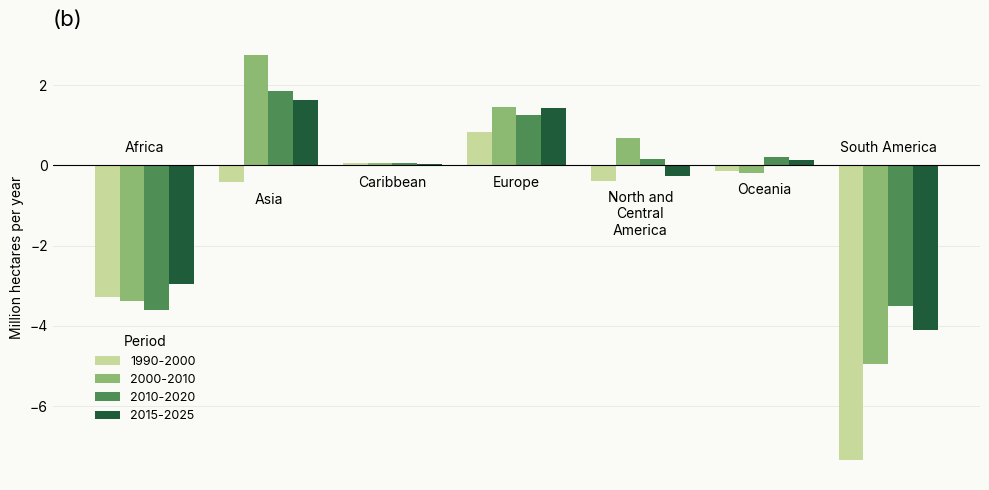

In [3]:
import textwrap

# Visual style
BG = "#FAFAF7"          # off-white, plus doux que blanc pur
TEXT = "#28322D"        # texte presque noir, légèrement vert/gris
MUTED_TEXT = "#666D69"
GRID = "#D9DDD9"
ZERO = "#343B37"

PERIOD_COLORS = [
    "#C7D99B",  # 1990-2000
    "#8DBA72",  # 2000-2010
    "#4F8F55",  # 2010-2020
    "#1F5D3A",  # 2015-2025
]

# Figure 1b - net annual change in forest area, plain matplotlib
region = territories.set_index("iso3").apply(
    lambda r: "Caribbean" if r["fra_subregion"] == "Caribbean" else r["fra_region"], axis=1)
wide = areas.pivot(index="iso3", columns="year", values="forest")
periods = {
    "1990-2000": (1990, 2000), 
    "2000-2010": (2000, 2010), 
    "2010-2020": (2010, 2020), 
    "2015-2025": (2015, 2025)
}
change = pd.DataFrame({p: (wide[b] - wide[a]) / (b - a) for p, (a, b) in periods.items()})
change = (change.groupby(region.reindex(change.index)).sum() / 1e6).sort_index()
x = np.arange(len(change.index))
width = 0.2

# Plot
fig, ax = plt.subplots(figsize=(10, 5), facecolor=BG)
ax.set_facecolor(BG)
for i, period in enumerate(change.columns):
    ax.bar(
        x + (i - 1.5) * width,
        change[period],
        width,
        label=period,
        color=PERIOD_COLORS[i],
        edgecolor="none",
        zorder=3
    )
ax.axhline(0, color="black", linewidth=0.8, zorder=10)
ax.set_xticks(x)

# Hide default x labels
ax.set_xticklabels([])
ax.tick_params(axis="x", length=0)

# Dynamic padding based on chart range
ymin = change.to_numpy().min()
ymax = change.to_numpy().max()
yrange = ymax - ymin

padding = 0.025 * yrange

# Place region labels on the least occupied side
for i, region_name in enumerate(change.index):

    values = change.loc[region_name].values

    max_pos = max(values.max(), 0)
    min_neg = min(values.min(), 0)

    positive_extent = max_pos
    negative_extent = abs(min_neg)

    if negative_extent > positive_extent:
        # Mostly negative bars -> label above
        label_y = max_pos + padding
        va = "bottom"

    else:
        # Mostly positive bars -> label below
        label_y = min_neg - padding
        va = "top"

    ax.text(
        x[i],
        label_y,
        textwrap.fill(region_name, width=14),
        ha="center",
        va=va,
        fontsize=10
    )

ax.set_ylabel("Million hectares per year")
ax.set_title("(b)", loc="left", fontsize=16, fontweight="bold")
ax.legend(
    title="Period",
    loc="upper center",
    bbox_to_anchor=(0.1, 0.35),
    ncol=1,
    frameon=False,
    fontsize=9,
    title_fontsize=10
)
for spine in ax.spines.values():
    spine.set_visible(False)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", alpha=0.25, linewidth=0.6)
plt.tight_layout()
save(fig, "figure1b")
plt.show()


[saved] figure1c.png / figure1c.pdf


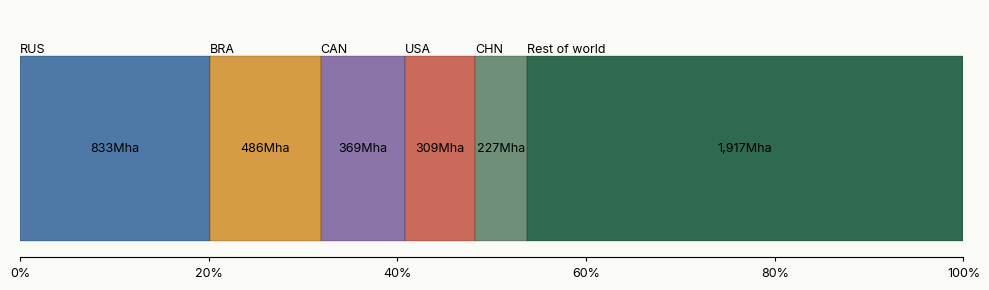

In [4]:
# Figure 1c - top 7 countries + rest of the world
MUTED_TEXT = "black"
COUNTRY_COLORS = {
    "RUS": "#4E79A7",           # bleu ardoise
    "BRA": "#D69C45",           # ocre
    "CAN": "#8B74A8",           # violet sourd
    "USA": "#C96A5B",           # terracotta
    "CHN": "#6F8F78",           # sauge
    "Rest of world": "#2D6A4F"  # vert forêt
}
forest_2025 = (
    areas.loc[areas["year"] == 2025]
    .set_index("iso3")["forest"]
    .sort_values(ascending=False)
)

# Convert to million hectares
top = forest_2025 / 1e6

# Top 7 + rest of world
parts = pd.concat([
    top.head(5),
    pd.Series({"Rest of world": top.iloc[5:].sum()})
])

# Share of global forest area (%)
shares = 100 * parts / parts.sum()

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 3), facecolor=BG)
ax.set_facecolor(BG)

left = 0.0

BAR_Y = 0
BAR_H = 0.6

for key, value in parts.items():

    width = shares[key]

    # Main segment
    ax.barh(
        BAR_Y,
        width,
        left=left,
        height=BAR_H,
        color=COUNTRY_COLORS[key],
        edgecolor=MUTED_TEXT,
        linewidth=.15,
        zorder=3
    )

    center = left + width / 2

    # ISO / group name above
    ax.text(
        left,
        BAR_Y + BAR_H / 2,
        key,
        ha="left",
        va="bottom",
        fontsize=9,
        fontweight="bold",
        color=MUTED_TEXT
    )

    # Mha inside segment
    ax.text(
        center,
        BAR_Y,
        f"{value:,.0f}Mha",
        ha="center",
        va="center",
        fontsize=9,
        color=MUTED_TEXT,
        fontweight="bold"
    )

    left += width


# ------------------------------------------------------------
# Styling
# ------------------------------------------------------------

ax.set_xlim(0, 100)
ax.set_ylim(-0.35, 0.45)

ax.set_yticks([])
# ax.set_xticks([])
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.set_xticklabels(
    ["0%", "20%", "40%", "60%", "80%", "100%"],
    fontsize=9,
    color=MUTED_TEXT
)

ax.tick_params(
    axis="x",
    length=3,
    width=0.8,
    color=MUTED_TEXT,
    pad=5
)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_color(MUTED_TEXT)
ax.spines["bottom"].set_linewidth(0.8)

plt.tight_layout()
save(fig, "figure1c")
plt.show()

In [5]:
TEXT_SCALE = 1.4   # multiplies every font size of this figure (1.0 = original sizes)

[saved] figure1.png / figure1.pdf


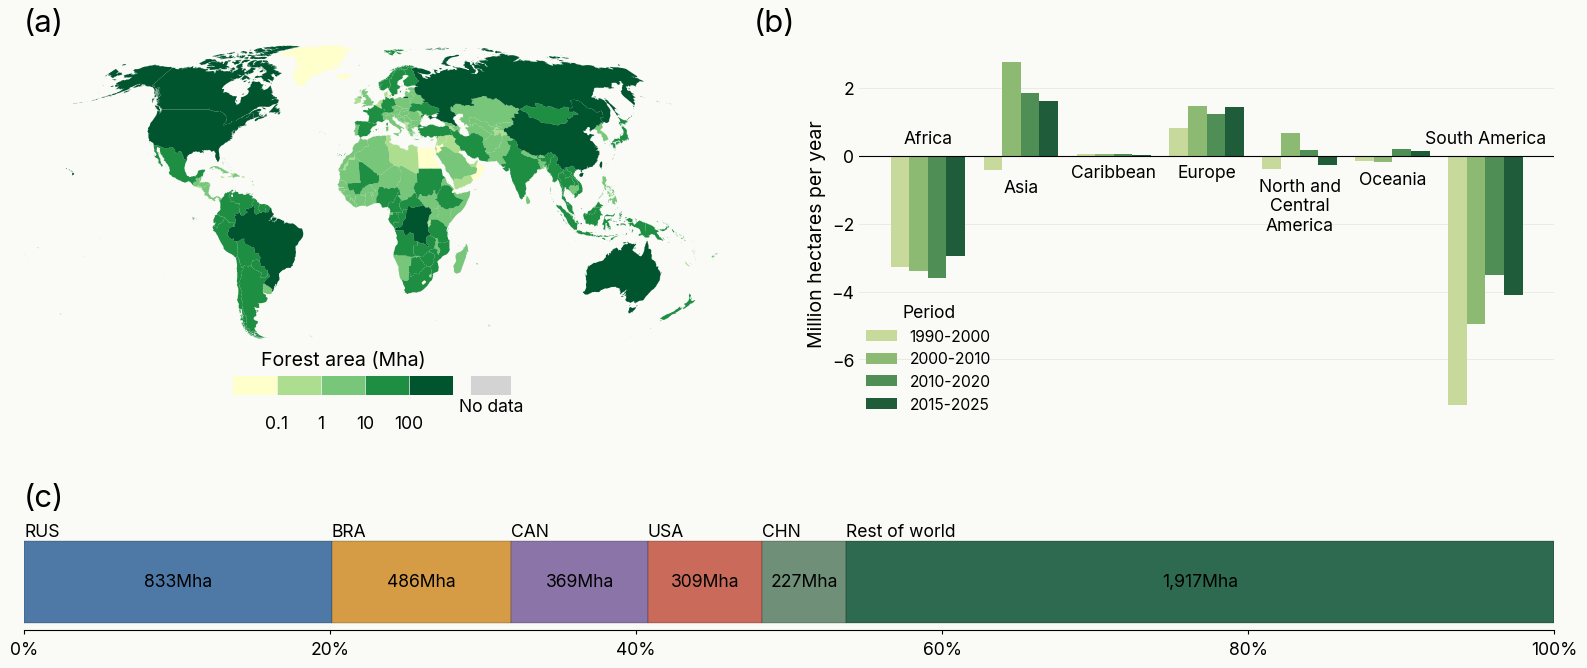

In [6]:
# Figure 1 - assembled: (a) | (b) on top, (c) below, same frame size for (a) and (b)
# Reuses the styling of cells 1a, 1b and 1c. Every axes is placed in inches so that
# (a) and (b) share the exact same box and the map (fixed aspect) fills its box.
import textwrap
from matplotlib.patches import Rectangle


def draw_map(ax):
    for category in [MISSING_LABEL, *BIN_LABELS]:
        subset = country_data.loc[country_data["_cat"] == category]
        if not subset.empty:
            subset.plot(ax=ax, color=colors[category], edgecolor="none", linewidth=0.2)
    xmin, ymin, xmax, ymax = world.total_bounds
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.axis("off")


def draw_map_legend(ax):
    seg_w, bar_h, y0, gap, nd_w = 1.0, 0.45, 0.45, 0.40, 0.9
    legend_colors = [colors[label] for label in BIN_LABELS]
    for i, color in enumerate(legend_colors):
        ax.add_patch(Rectangle((i * seg_w, y0), seg_w, bar_h, facecolor=color, edgecolor="none"))
    for x in range(1, len(legend_colors)):
        ax.axvline(x, ymin=y0, ymax=y0 + bar_h, color="white", linewidth=0.5)
    ax.set_xticks([1, 2, 3, 4])
    ax.set_xticklabels(["0.1", "1", "10", "100"], fontsize=9 * TEXT_SCALE)
    ax.tick_params(axis="x", length=0, pad=1)
    no_data_x = len(legend_colors) * seg_w + gap
    ax.add_patch(Rectangle((no_data_x, y0), nd_w, bar_h, facecolor=MISSING_COLOR, edgecolor="none"))
    ax.text(no_data_x + nd_w / 2, y0 - 0.08, "No data", fontsize=9 * TEXT_SCALE, ha="center", va="top")
    ax.text(2.5 * seg_w, 1.05, "Forest area (Mha)", fontsize=10 * TEXT_SCALE, ha="center", va="bottom")
    ax.set_xlim(0, no_data_x + nd_w)
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_facecolor("none")
    for spine in ax.spines.values():
        spine.set_visible(False)


def draw_change(ax):
    # local positions: the 1c cell reuses the global names `x` and `width`
    positions, bar_w = np.arange(len(change.index)), 0.2
    for i, period in enumerate(change.columns):
        ax.bar(positions + (i - 1.5) * bar_w, change[period], bar_w, label=period,
               color=PERIOD_COLORS[i], edgecolor="none", zorder=3)
    ax.axhline(0, color="black", linewidth=0.8, zorder=10)
    ax.set_xticks(positions)
    ax.set_xticklabels([])
    ax.tick_params(axis="x", length=0)
    values = change.to_numpy()
    padding = 0.025 * (values.max() - values.min())
    for i, name in enumerate(change.index):
        row = change.loc[name].values
        top, bottom = max(row.max(), 0), min(row.min(), 0)
        above = abs(bottom) > top
        ax.text(positions[i], top + padding if above else bottom - padding, textwrap.fill(name, width=14),
                ha="center", va="bottom" if above else "top", fontsize=9 * TEXT_SCALE)
    ax.set_ylabel("Million hectares per year", fontsize=10 * TEXT_SCALE)
    ax.tick_params(axis="y", labelsize=9 * TEXT_SCALE)
    ax.legend(title="Period", loc="upper center", bbox_to_anchor=(0.1, 0.35), ncol=1, frameon=False,
              fontsize=8 * TEXT_SCALE, title_fontsize=9 * TEXT_SCALE)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="y", alpha=0.25, linewidth=0.6)
    ax.set_facecolor(BG)


def draw_top_countries(ax):
    MUTED_TEXT = "black"
    left = 0.0
    for key, value in parts.items():
        share = shares[key]
        ax.barh(0, share, left=left, height=0.6, color=COUNTRY_COLORS[key], edgecolor=MUTED_TEXT, linewidth=0.15, zorder=3)
        ax.text(left, 0.3, key, ha="left", va="bottom", fontsize=9 * TEXT_SCALE, fontweight="bold", color=MUTED_TEXT)
        ax.text(left + share / 2, 0, f"{value:,.0f}Mha", ha="center", va="center", fontsize=9 * TEXT_SCALE,
                fontweight="bold", color=MUTED_TEXT)
        left += share
    ax.set_xlim(0, 100)
    ax.set_ylim(-0.35, 0.45)
    ax.set_yticks([])
    ax.set_xticks([0, 20, 40, 60, 80, 100])
    ax.set_xticklabels(["0%", "20%", "40%", "60%", "80%", "100%"], fontsize=9 * TEXT_SCALE, color=MUTED_TEXT)
    ax.tick_params(axis="x", length=3, width=0.8, color=MUTED_TEXT, pad=5)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.spines["bottom"].set_visible(True)
    ax.spines["bottom"].set_color(MUTED_TEXT)
    ax.spines["bottom"].set_linewidth(0.8)
    ax.set_facecolor(BG)


# ---- Layout in inches -------------------------------------------------------
FIG_W = 16.0
MARGIN_L, MARGIN_R = 0.35, 0.35
GAP_AB = 1.0 * TEXT_SCALE        # room for the y-axis label of (b)
PANEL_W = (FIG_W - MARGIN_L - MARGIN_R - GAP_AB) / 2
xmin, ymin, xmax, ymax = world.total_bounds
MAP_H = PANEL_W / ((xmax - xmin) / (ymax - ymin))   # the map fills the panel width exactly
LEGEND_H = 0.55 * TEXT_SCALE
PANEL_H = MAP_H + LEGEND_H       # (a) = map + legend, (b) = same box
LABEL_H = 0.45 * TEXT_SCALE      # space for the (a)/(b)/(c) labels
C_H, C_TICKS = 1.1, 0.40 * TEXT_SCALE
GAP_TOP_C = 0.35
FIG_H = 0.15 + C_TICKS + C_H + LABEL_H + GAP_TOP_C + PANEL_H + LABEL_H

fig = plt.figure(figsize=(FIG_W, FIG_H), facecolor=BG)


def add_axes_in(x, y, w, h):
    """Add axes from a box given in inches (origin bottom-left of the figure)."""
    return fig.add_axes([x / FIG_W, y / FIG_H, w / FIG_W, h / FIG_H])


y_c = 0.15 + C_TICKS
y_top = y_c + C_H + LABEL_H + GAP_TOP_C
x_b = MARGIN_L + PANEL_W + GAP_AB

ax_map = add_axes_in(MARGIN_L, y_top + LEGEND_H, PANEL_W, MAP_H)
ax_leg = add_axes_in(MARGIN_L + PANEL_W * 0.30, y_top + 0.08, PANEL_W * 0.40, LEGEND_H * 0.55)
ax_b = add_axes_in(x_b, y_top, PANEL_W, PANEL_H)
ax_c = add_axes_in(MARGIN_L, y_c, FIG_W - MARGIN_L - MARGIN_R, C_H)

draw_map(ax_map)
draw_map_legend(ax_leg)
draw_change(ax_b)
draw_top_countries(ax_c)

label_style = dict(fontsize=16 * TEXT_SCALE, fontweight="bold", ha="left", va="bottom")
fig.text(MARGIN_L / FIG_W, (y_top + PANEL_H + 0.08) / FIG_H, "(a)", **label_style)
fig.text((x_b - 0.75 * TEXT_SCALE) / FIG_W, (y_top + PANEL_H + 0.08) / FIG_H, "(b)", **label_style)
fig.text(MARGIN_L / FIG_W, (y_c + C_H + 0.08) / FIG_H, "(c)", **label_style)

save(fig, "figure1")
plt.show()


## Figure 2 - Gross forest-biomass additions

(a) national annual additions to living biomass, (b) contribution of the four FAO GEZ biomes, (c) annual additions by development group. Gibbs/GFW source pixels classified as mangrove are excluded from rate estimation; FRA surface areas subtract only report-documented mangrove hectares classified as Forest.

[saved] figure2.png / figure2.pdf


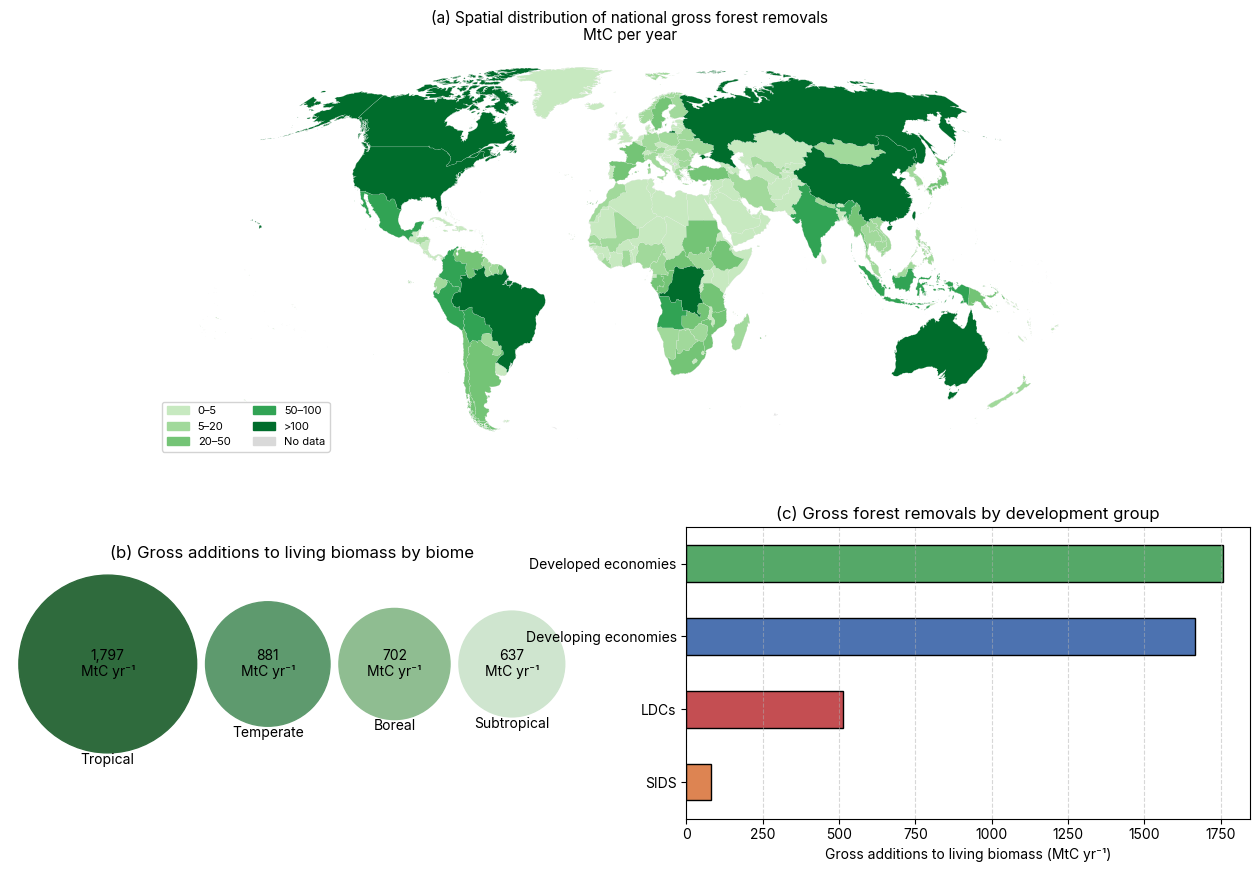

In [7]:
uptake_mtc = gcw.set_index("iso3")["uptake_tco2_yr_mean"] / CO2_PER_C / 1e6

biome_area = pd.read_csv(SUMMARY / "forest_area_by_biome.csv").query("variant == 'documented_overlap_removed'")
rates = pd.read_csv(SUMMARY / "gfw_gibbs_biome_rates.csv").set_index("biome")["rate_tc_ha_yr_mean"]
biome_mtc = (biome_area.groupby("biome")["area_ha"].sum() * rates / 1e6).sort_values(ascending=False)

fig = plt.figure(figsize=(16, 10))
grid = fig.add_gridspec(2, 2, height_ratios=[1.4, 1])
ax = fig.add_subplot(grid[0, :])
choropleth(ax, uptake_mtc, [-np.inf, 5, 20, 50, 100, np.inf], ["0-5", "5-20", "20-50", "50-100", ">100"], GREENS[1:6],
           "(a) Spatial distribution of national gross forest removals", "MtC per year")

ax = fig.add_subplot(grid[1, 0])
x = 0.0
for (biome, value), color in zip(biome_mtc.items(), ["#2f6b3d", "#5e9a6e", "#8fbd91", "#cfe5cf"]):
    radius = np.sqrt(value / biome_mtc.max())
    x += radius
    ax.add_patch(plt.Circle((x, 0), radius, color=color))
    ax.text(x, 0, f"{value:,.0f}\nMtC yr⁻¹", ha="center", va="center")
    ax.text(x, -radius - 0.12, biome.capitalize(), ha="center")
    x += radius + 0.1
ax.set_xlim(-0.1, x)
ax.set_ylim(-1.3, 1.1)
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title("(b) Gross additions to living biomass by biome")

ax = fig.add_subplot(grid[1, 1])
groups = uptake_mtc.groupby(gcw.set_index("iso3")["groups"]).sum().sort_values()
groups.plot.barh(ax=ax, color=[GROUP_COLORS.get(g, "grey") for g in groups.index], edgecolor="black")
ax.set_xlabel("Gross additions to living biomass (MtC yr⁻¹)")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_title("(c) Gross forest removals by development group")
save(fig, "figure2")

[saved] figure2.png / figure2.pdf


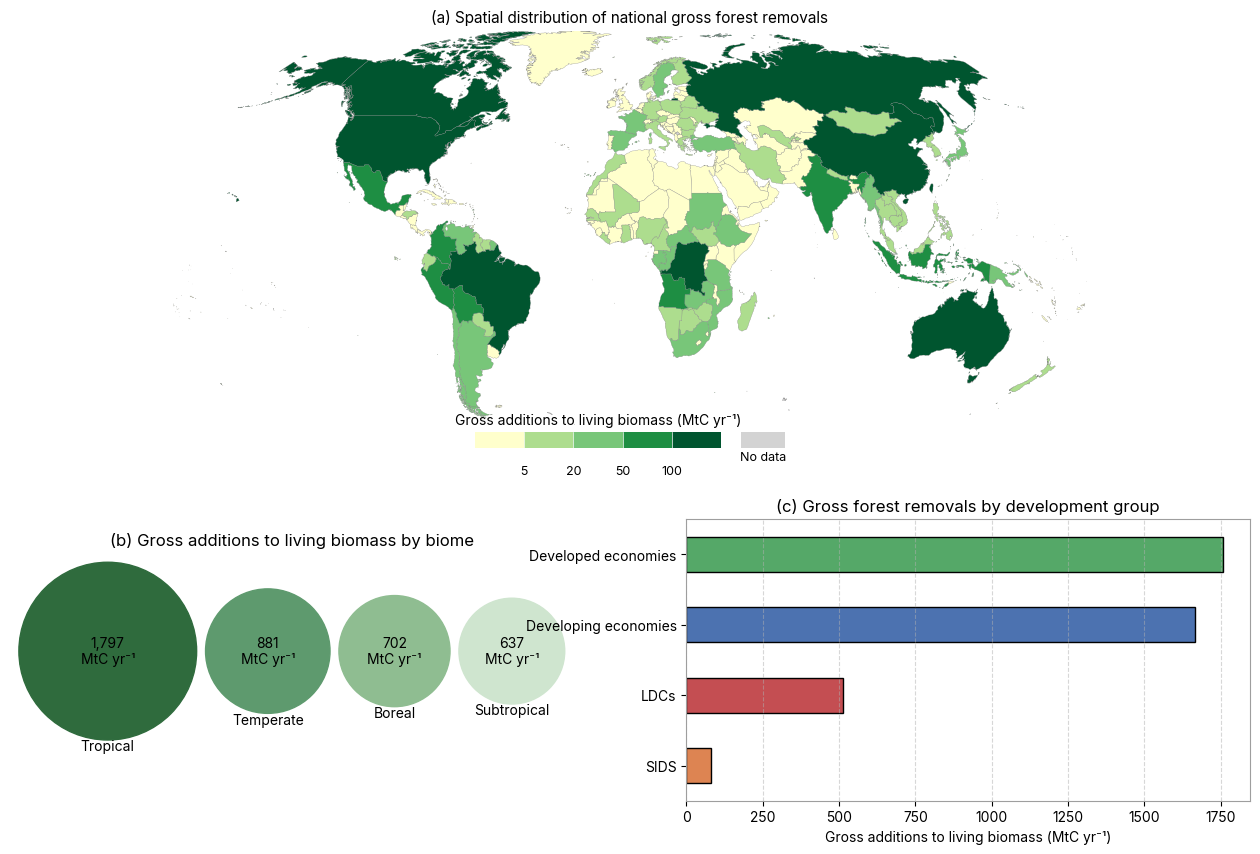

In [8]:
# Figure 2 - same as above, with (a) drawn like the figure 1 map and grey spines on (c)
from matplotlib.patches import Rectangle

UPTAKE_BINS = [-np.inf, 5, 20, 50, 100, np.inf]
UPTAKE_LABELS = ["0-5", "5-20", "20-50", "50-100", ">100"]
UPTAKE_TICKS = ["5", "20", "50", "100"]          # inner bin edges, as on the figure 1 legend
SPINE_GREY = "#9E9E9E"

uptake_mtc = gcw.set_index("iso3")["uptake_tco2_yr_mean"] / CO2_PER_C / 1e6
biome_area = pd.read_csv(SUMMARY / "forest_area_by_biome.csv").query("variant == 'documented_overlap_removed'")
rates = pd.read_csv(SUMMARY / "gfw_gibbs_biome_rates.csv").set_index("biome")["rate_tc_ha_yr_mean"]
biome_mtc = (biome_area.groupby("biome")["area_ha"].sum() * rates / 1e6).sort_values(ascending=False)


def segmented_legend(ax, seg_colors, ticks, title):
    """Horizontal segmented legend with a separate 'No data' box (figure 1 style)."""
    seg_w, bar_h, y0, gap, nd_w = 1.0, 0.45, 0.45, 0.40, 0.9
    for i, color in enumerate(seg_colors):
        ax.add_patch(Rectangle((i * seg_w, y0), seg_w, bar_h, facecolor=color, edgecolor="none"))
    for x_sep in range(1, len(seg_colors)):
        ax.axvline(x_sep, ymin=y0, ymax=y0 + bar_h, color="white", linewidth=0.5)
    ax.set_xticks(range(1, len(seg_colors)))
    ax.set_xticklabels(ticks, fontsize=9)
    ax.tick_params(axis="x", length=0, pad=1)
    no_data_x = len(seg_colors) * seg_w + gap
    ax.add_patch(Rectangle((no_data_x, y0), nd_w, bar_h, facecolor=MISSING_COLOR, edgecolor="none"))
    ax.text(no_data_x + nd_w / 2, y0 - 0.08, "No data", fontsize=9, ha="center", va="top")
    ax.text(len(seg_colors) * seg_w / 2, 1.05, title, fontsize=10, ha="center", va="bottom")
    ax.set_xlim(0, no_data_x + nd_w)
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.set_facecolor("none")
    for spine in ax.spines.values():
        spine.set_visible(False)


fig = plt.figure(figsize=(16, 10))
grid = fig.add_gridspec(2, 2, height_ratios=[1.4, 1], hspace=0.28)

# (a) map, figure 1 style: same palette, no borders, segmented legend below the map
ax = fig.add_subplot(grid[0, :])
uptake_data = world.merge(uptake_mtc.rename("value"), left_on="iso3", right_index=True, how="left")
uptake_data["_cat"] = pd.cut(uptake_data["value"], bins=UPTAKE_BINS, labels=UPTAKE_LABELS).astype(object)
uptake_data["_cat"] = uptake_data["_cat"].fillna(MISSING_LABEL)
uptake_colors = {MISSING_LABEL: MISSING_COLOR} | {label: FOREST_CMAP(i) for i, label in enumerate(UPTAKE_LABELS)}
for category in [MISSING_LABEL, *UPTAKE_LABELS]:
    subset = uptake_data.loc[uptake_data["_cat"] == category]
    if not subset.empty:
        subset.plot(ax=ax, color=uptake_colors[category], edgecolor="gray", linewidth=0.2)
xmin, ymin, xmax, ymax = world.total_bounds
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title("(a) Spatial distribution of national gross forest removals", fontsize=11)
segmented_legend(ax.inset_axes([0.33, -0.10, 0.34, 0.09]),
                 [uptake_colors[label] for label in UPTAKE_LABELS], UPTAKE_TICKS, "Gross additions to living biomass (MtC yr⁻¹)")

# (b) biome bubbles - unchanged
ax = fig.add_subplot(grid[1, 0])
x = 0.0
for (biome, value), color in zip(biome_mtc.items(), ["#2f6b3d", "#5e9a6e", "#8fbd91", "#cfe5cf"]):
    radius = np.sqrt(value / biome_mtc.max())
    x += radius
    ax.add_patch(plt.Circle((x, 0), radius, color=color))
    ax.text(x, 0, f"{value:,.0f}\nMtC yr⁻¹", ha="center", va="center")
    ax.text(x, -radius - 0.12, biome.capitalize(), ha="center")
    x += radius + 0.1
ax.set_xlim(-0.1, x)
ax.set_ylim(-1.3, 1.1)
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title("(b) Gross additions to living biomass by biome")

# (c) development groups - unchanged except grey spines
ax = fig.add_subplot(grid[1, 1])
groups = uptake_mtc.groupby(gcw.set_index("iso3")["groups"]).sum().sort_values()
groups.plot.barh(ax=ax, color=[GROUP_COLORS.get(g, "grey") for g in groups.index], edgecolor="black")
ax.set_xlabel("Gross additions to living biomass (MtC yr⁻¹)")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.5)
ax.set_title("(c) Gross forest removals by development group")
for spine in ax.spines.values():
    spine.set_color(SPINE_GREY)
save(fig, "figure2")
plt.show()


## Figure 3 - Green Carbon Wealth

(a) GCW per capita, (b) GCW/GDP for the top 30 countries, (c) total GCW, (d) GCW per capita for the top 30 countries.

[saved] figure3.png / figure3.pdf


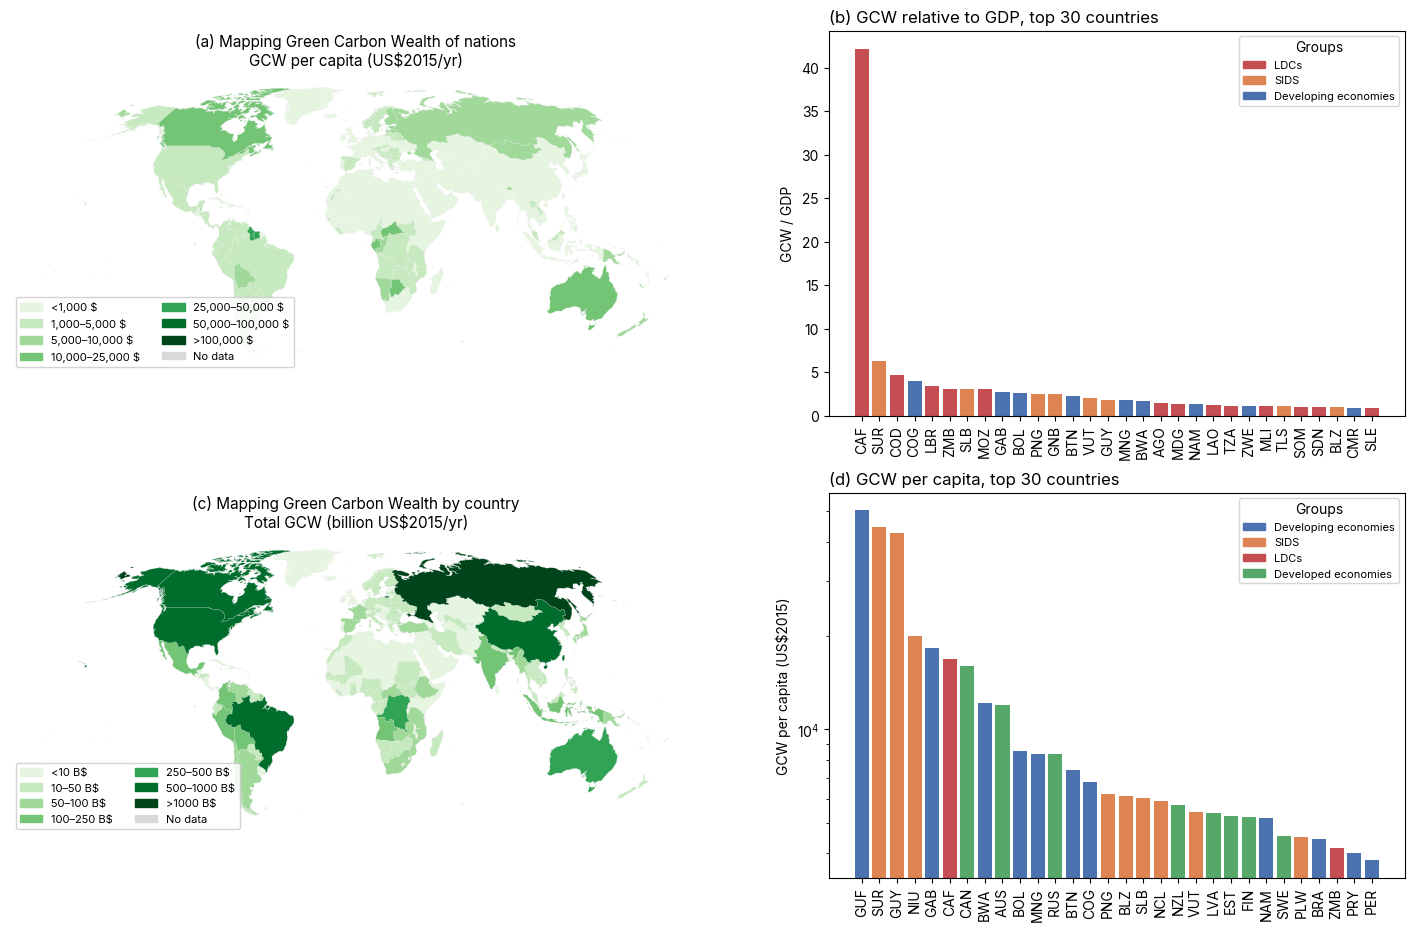

In [9]:
g = gcw.set_index("iso3")
fig, axes = plt.subplots(2, 2, figsize=(18, 11), gridspec_kw={"width_ratios": [1.2, 1]})

choropleth(axes[0, 0], g["gcw_per_capita_usd2015"], [-np.inf, 1e3, 5e3, 1e4, 2.5e4, 5e4, 1e5, np.inf],
           ["<1,000 $", "1,000-5,000 $", "5,000-10,000 $", "10,000-25,000 $", "25,000-50,000 $", "50,000-100,000 $", ">100,000 $"],
           GREENS, "(a) Mapping Green Carbon Wealth of nations", "GCW per capita (US$2015/yr)")
choropleth(axes[1, 0], g["gcw_usd2015_yr_mean"] / 1e9, [-np.inf, 10, 50, 100, 250, 500, 1000, np.inf],
           ["<10 B$", "10-50 B$", "50-100 B$", "100-250 B$", "250-500 B$", "500-1000 B$", ">1000 B$"],
           GREENS, "(c) Mapping Green Carbon Wealth by country", "Total GCW (billion US$2015/yr)")


def top30(ax, column, title, ylabel, log=False):
    top = g[column].dropna().sort_values(ascending=False).head(30)
    ax.bar(top.index, top, color=[GROUP_COLORS.get(x, "grey") for x in g.loc[top.index, "groups"]])
    ax.set_title(title, loc="left")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=90)
    if log:
        ax.set_yscale("log")
    present = g.loc[top.index, "groups"].dropna().unique()
    ax.legend(handles=[Patch(color=GROUP_COLORS[k], label=k) for k in present if k in GROUP_COLORS], title="Groups", fontsize=8)


top30(axes[0, 1], "gcw_share_of_gdp", "(b) GCW relative to GDP, top 30 countries", "GCW / GDP")
top30(axes[1, 1], "gcw_per_capita_usd2015", "(d) GCW per capita, top 30 countries", "GCW per capita (US$2015)", log=True)
save(fig, "figure3")

[saved] figure3.png / figure3.pdf


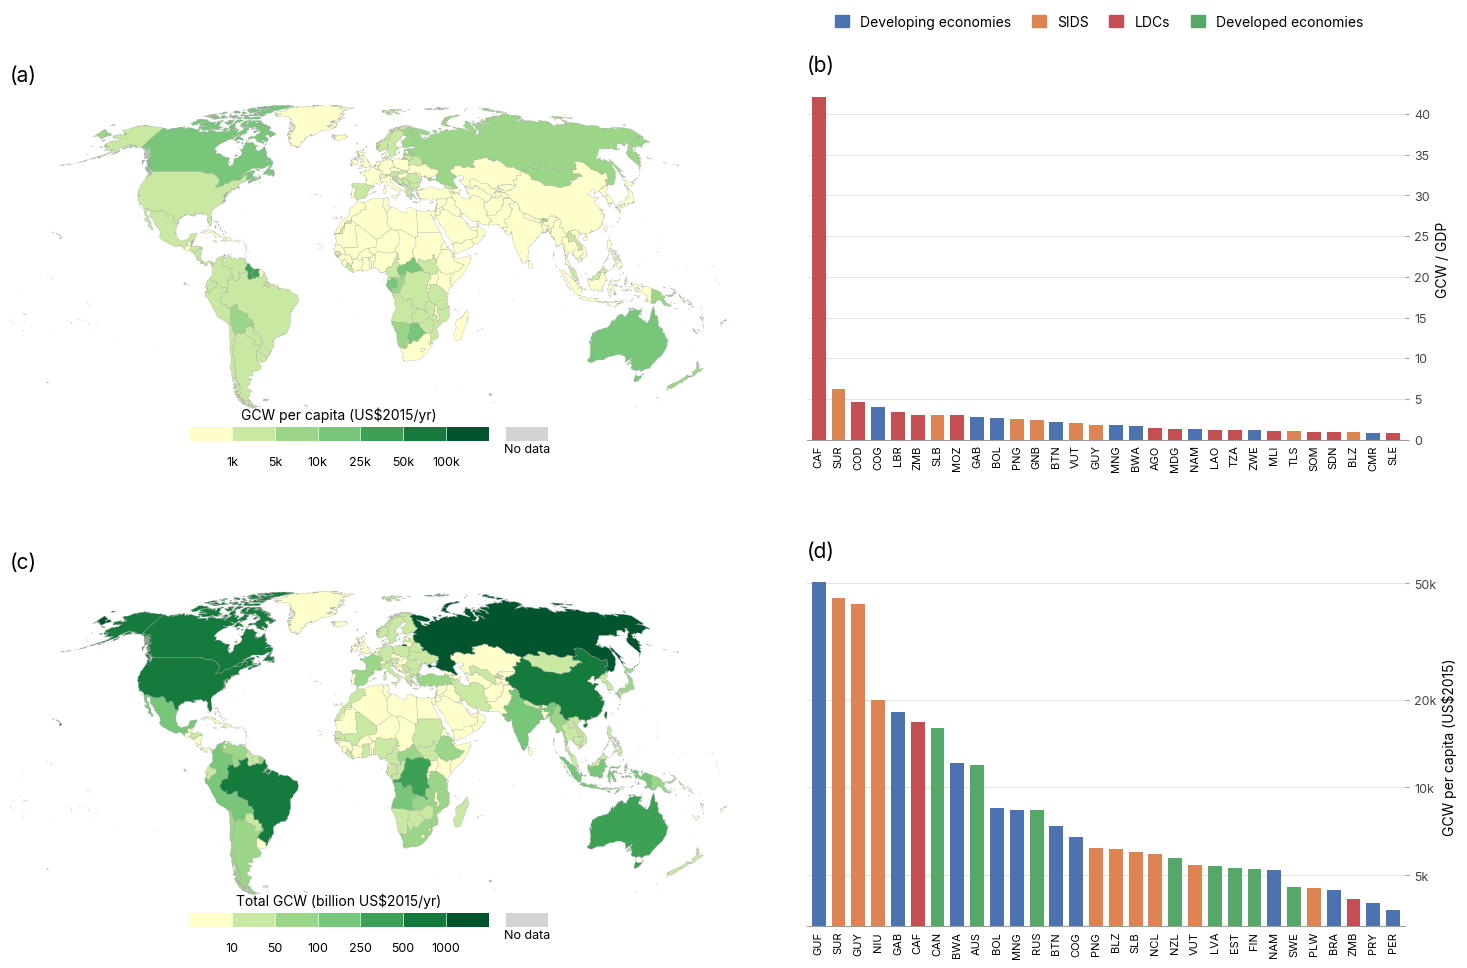

In [10]:
# Figure 3 - figure 1 style maps (grey borders), simple bar charts with one shared legend, panel letters only
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

EDGE_GREY = "#9E9E9E"
AXIS_GREY = "#9E9E9E"
MAP_CMAP = LinearSegmentedColormap.from_list("forest", COL_LIST)   # figure 1 palette, stretched to 7 classes

PER_CAPITA_BINS = [-np.inf, 1e3, 5e3, 1e4, 2.5e4, 5e4, 1e5, np.inf]
PER_CAPITA_TICKS = ["1k", "5k", "10k", "25k", "50k", "100k"]
TOTAL_BINS = [-np.inf, 10, 50, 100, 250, 500, 1000, np.inf]
TOTAL_TICKS = ["10", "50", "100", "250", "500", "1000"]

g = gcw.set_index("iso3")


def class_map(ax, values, bins, ticks, legend_title):
    """Figure 1 style choropleth: sequential classes, grey borders, segmented legend below."""
    n_classes = len(bins) - 1
    class_colors = [MAP_CMAP(i / (n_classes - 1)) for i in range(n_classes)]
    data = world.merge(values.rename("value"), left_on="iso3", right_index=True, how="left")
    data["_cls"] = pd.cut(data["value"], bins=bins, labels=False)
    data.loc[data["_cls"].isna()].plot(ax=ax, color=MISSING_COLOR, edgecolor=EDGE_GREY, linewidth=0.2)
    for i, color in enumerate(class_colors):
        subset = data.loc[data["_cls"] == i]
        if not subset.empty:
            subset.plot(ax=ax, color=color, edgecolor=EDGE_GREY, linewidth=0.2)
    xmin, ymin, xmax, ymax = world.total_bounds
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.axis("off")

    legend = ax.inset_axes([0.25, -0.13, 0.5, 0.10])
    seg_w, bar_h, y0, gap, nd_w = 1.0, 0.45, 0.45, 0.40, 1.0
    for i, color in enumerate(class_colors):
        legend.add_patch(Rectangle((i * seg_w, y0), seg_w, bar_h, facecolor=color, edgecolor="none"))
    for x_sep in range(1, n_classes):
        legend.axvline(x_sep, ymin=y0, ymax=y0 + bar_h, color="white", linewidth=0.5)
    legend.set_xticks(range(1, n_classes))
    legend.set_xticklabels(ticks, fontsize=9)
    legend.tick_params(axis="x", length=0, pad=1)
    no_data_x = n_classes * seg_w + gap
    legend.add_patch(Rectangle((no_data_x, y0), nd_w, bar_h, facecolor=MISSING_COLOR, edgecolor="none"))
    legend.text(no_data_x + nd_w / 2, y0 - 0.08, "No data", fontsize=9, ha="center", va="top")
    legend.text(n_classes * seg_w / 2, 1.05, legend_title, fontsize=10, ha="center", va="bottom")
    legend.set_xlim(0, no_data_x + nd_w)
    legend.set_ylim(0, 1)
    legend.set_yticks([])
    legend.set_facecolor("none")
    for spine in legend.spines.values():
        spine.set_visible(False)


def top30_bars(ax, column, ylabel, log=False):
    """Simple bar chart: right and bottom spines, horizontal grid, colors by country group."""
    top = g[column].dropna().sort_values(ascending=False).head(30)
    ax.bar(top.index, top, color=[GROUP_COLORS.get(k, "grey") for k in g.loc[top.index, "groups"]],
           width=0.7, edgecolor="none", zorder=3)
    if log:
        ax.set_yscale("log")
        steps = [v for v in (1e3, 2e3, 5e3, 1e4, 2e4, 5e4, 1e5, 2e5, 5e5) if top.min() * 0.8 <= v <= top.max() * 1.2]
        ax.yaxis.set_major_locator(FixedLocator(steps))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}k"))
        ax.yaxis.set_minor_locator(NullLocator())
    ax.set_ylabel(ylabel)
    ax.yaxis.set_label_position("right")
    ax.yaxis.tick_right()
    ax.grid(axis="y", color="#E3E3E3", linewidth=0.7, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", rotation=90, labelsize=8, length=0)
    ax.tick_params(axis="y", labelsize=9, colors="#444444", length=3, color=AXIS_GREY)
    ax.set_xlim(-0.6, len(top) - 0.4)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    for side in ["bottom"]:
        ax.spines[side].set_color(AXIS_GREY)
    return set(g.loc[top.index, "groups"].dropna())


fig, axes = plt.subplots(2, 2, figsize=(18, 11), gridspec_kw={"width_ratios": [1.2, 1], "hspace": 0.35, "wspace": 0.12})

class_map(axes[0, 0], g["gcw_per_capita_usd2015"], PER_CAPITA_BINS, PER_CAPITA_TICKS, "GCW per capita (US$2015/yr)")
class_map(axes[1, 0], g["gcw_usd2015_yr_mean"] / 1e9, TOTAL_BINS, TOTAL_TICKS, "Total GCW (billion US$2015/yr)")
groups_b = top30_bars(axes[0, 1], "gcw_share_of_gdp", "GCW / GDP")
groups_d = top30_bars(axes[1, 1], "gcw_per_capita_usd2015", "GCW per capita (US$2015)", log=True)

# one legend shared by (b) and (d), above the bar charts
shown = [k for k in GROUP_COLORS if k in groups_b | groups_d]
fig.legend(handles=[Patch(color=GROUP_COLORS[k], label=k) for k in shown], loc="upper center",
           bbox_to_anchor=(0.73, 0.95), ncol=len(shown), frameon=False, fontsize=10,
           handlelength=1.0, handleheight=1.0, columnspacing=1.5)

for ax, letter in zip([axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]], "abcd"):
    ax.set_title(f"({letter})", loc="left", fontsize=15, fontweight="bold")

save(fig, "figure3")
plt.show()


## Figure 4 - Natural Carbon Wealth decomposition: GCW vs BCW

By continent and by country group, from `table2_by_continent.csv` and `table3_by_group.csv`.

[saved] figure4.png / figure4.pdf


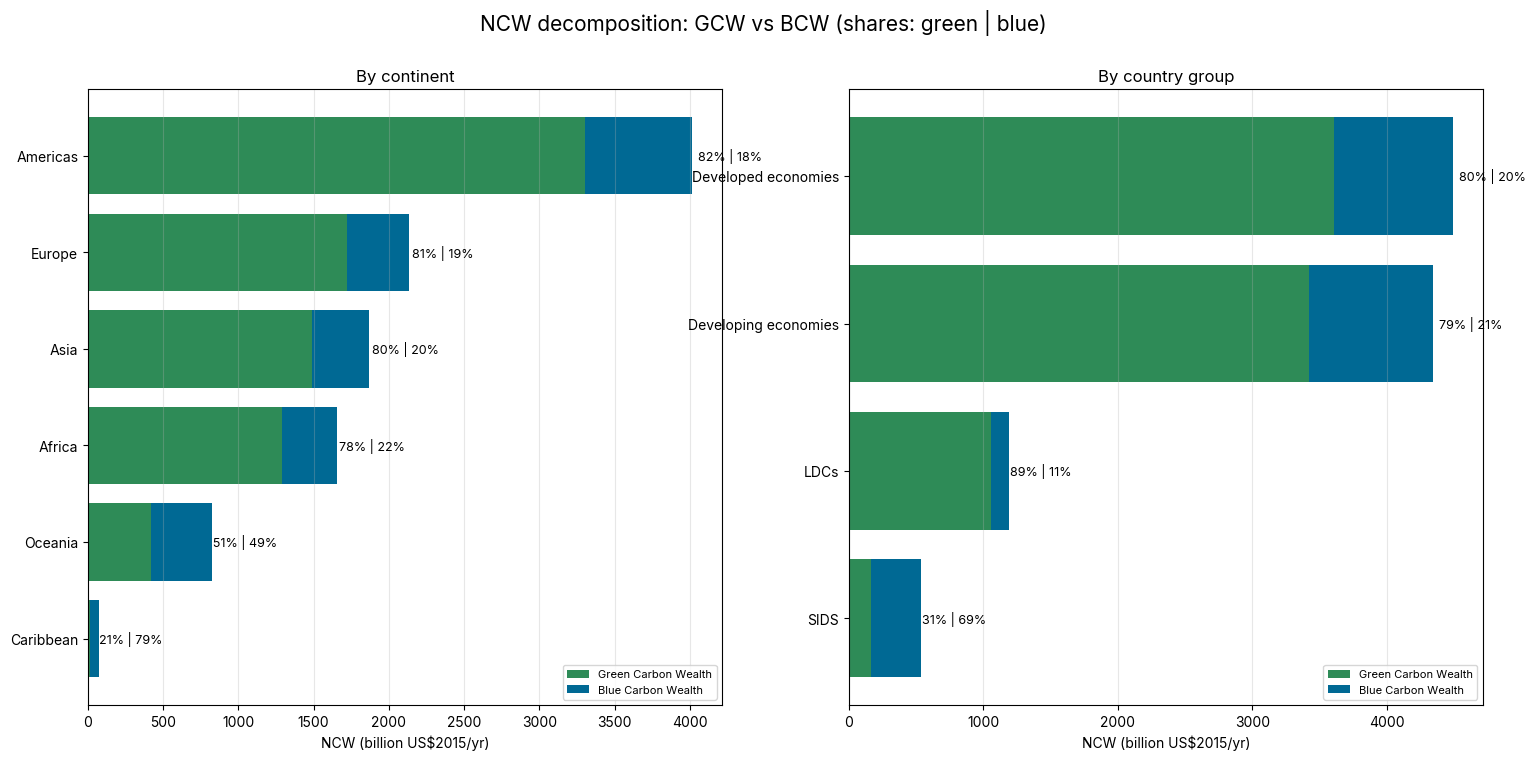

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, table, key, title in [(axes[0], by_continent, "continent", "By continent"), (axes[1], by_group, "groups", "By country group")]:
    data = table.loc[table[key] != "Unclassified"].set_index(key).sort_values("ncw_usd2015_yr_mean")
    green, blue = data["gcw_usd2015_yr_mean"] / 1e9, data["bcw_usd2015_yr_mean"] / 1e9
    ax.barh(data.index, green, color="#2e8b57", label="Green Carbon Wealth")
    ax.barh(data.index, blue, left=green, color="#006994", label="Blue Carbon Wealth")
    for y, (gv, bv) in enumerate(zip(green, blue)):
        total = gv + bv
        ax.text(total * 1.01, y, f"{100 * gv / total:.0f}% | {100 * bv / total:.0f}%", va="center", fontsize=9)
    ax.set_xlabel("NCW (billion US$2015/yr)")
    ax.set_title(title, fontweight="bold")
    ax.grid(axis="x", alpha=0.3)
    ax.legend(loc="lower right")
fig.suptitle("NCW decomposition: GCW vs BCW (shares: green | blue)", fontsize=15, fontweight="bold")
save(fig, "figure4")

## Figure 5 - Global distribution of Natural Carbon Wealth

(a) total NCW, (b) NCW per capita.

[saved] figure5.png / figure5.pdf


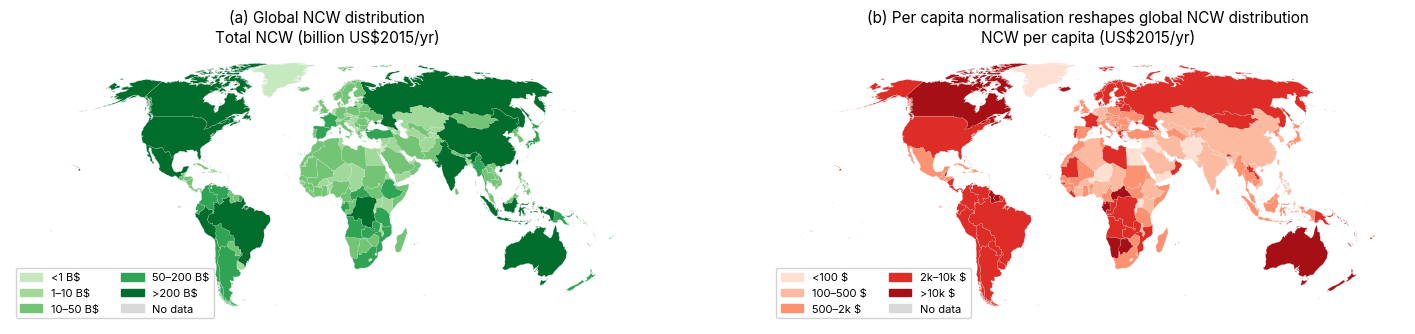

In [12]:
n = ncw.set_index("iso3")
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
choropleth(axes[0], n["ncw_usd2015_yr_mean"] / 1e9, [-np.inf, 1, 10, 50, 200, np.inf], ["<1 B$", "1-10 B$", "10-50 B$", "50-200 B$", ">200 B$"],
           GREENS[1:6], "(a) Global NCW distribution", "Total NCW (billion US$2015/yr)")
choropleth(axes[1], n["ncw_per_capita_usd2015"], [-np.inf, 100, 500, 2e3, 1e4, np.inf], ["<100 $", "100-500 $", "500-2k $", "2k-10k $", ">10k $"],
           ["#fee0d2", "#fcbba1", "#fc9272", "#de2d26", "#a50f15"], "(b) Per capita normalisation reshapes global NCW distribution",
           "NCW per capita (US$2015/yr)")
save(fig, "figure5")